# ECMI 2026: paprastas bazinis modelis (GRU autoenkoderis)

Tikslas: pažiūrėti, ko galima pasiekti **paėmus paprastą paruoštą modelį be jokios fizikos**. Be to, patikriname, ar mūsų vertinimo kodas gerai atkartoja straipsnio rezultatus (Savic ir kt., 2021).

Eiga: 1) duomenų stulpeliai ir kodėl renkamės būtent šiuos, 2) vertinimo metrika, 3) straipsnio autoenkoderio atkartojimas kaip patikra, 4) GRU autoenkoderis ir variantai, 5) klaidų laiko eilutė, 6) visų eksperimentų santrauka (paskutinis langelis).

Kiekvienas apmokytas modelis įrašo eilutes į `experiments_anomaly.csv`. Pakartotinis paleidimas prideda naujas eilutes, istorija nesinaikina.

## 1. Duomenys: ką matuoja kiekvienas stulpelis ir kuriuos naudojame

Kiekviena eilutė apibendrina vieną GNSS intervalą (apie 10 s; kovą laiko žymos apvalintos iki minutės, todėl 5-6 eilutės turi tą pačią žymą). GPS reikšmės yra momentinės, o akselerometro ir magnetometro stulpeliai yra **RMS** (šaknis iš kvadratų vidurkio) visų ~15 ms mėginių, patekusių į tą intervalą.

| Stulpelis | Ką rodo | Naudojame? | Kodėl |
|---|---|---|---|
| `timestamp` | Eilutės laikas. Sausį ~10 s žingsnis, kovą apvalinta iki minutės (5-6 eilutės turi tą patį laiką) | tik tvarkai | Ne požymis. Pagal jį jungiame eilutes į langus ir susiejame su anomalijų laikais |
| `GPS_lat`, `GPS_lon` | Padėtis. Reikšmė 0, 0 reiškia, kad nėra GPS fiksacijos | ne | Straipsnyje sakoma, kad testo duomenyse nėra vietos anomalijų. 7-12 % eilučių be fiksacijos |
| `GPS_alt` | Aukštis (m), triukšmingas, neigiamas reiškia klaidą | tik palyginime | Rodo palydovų matomumą, o ne dėžės elgesį |
| `GPS_speed` | Greitis. Vienetas nenurodytas, iš koordinačių pokyčio išėjo apie 2 kartus daugiau nei m/s, tad greičiausiai **mazgai**. Kovo mėn. visada 0 | tik palyginime | Kovą nieko nerodo, nors padėtis keičiasi |
| `GPS_num_sats` | Matomų palydovų skaičius | tik palyginime | Radijo sąlygos, ne dėžės judėjimas |
| `ACC_x/y/z_RMS` | Akselerometras (m/s²) trimis ašimis. Nejudanti dėžė rodo ~9,8 (sunkis) vienoje ašyje | **taip** | Tiesiogiai matuoja purtymą ir dėžės padėtį |
| `ACC_samples` | Kiek ~15 ms mėginių suvidurkinta (~546 per 8 s) | tik palyginime | Apskaitos skaičius, ne fizinis signalas |
| `MAG_x/y/z_RMS` | Magnetometras (µT) trimis ašimis | **taip** | Verčiant dėžę lauko komponentės šokteli, papildo akselerometrą |
| `MAG_samples` | Visada lygus `ACC_samples` | tik palyginime | Dublikatas |

**Kodėl 6 IMU stulpeliai.** Straipsnis sako, kad testo anomalijos yra tyčia sukeltas dėžės **purtymas ir vertimas**. Abu šie dalykai yra fizinis dėžės judėjimas, o jį matuoja tik IMU. GPS stulpeliai arba nieko nesako (kovo mėn. greitis 0), arba rodo ne dėžę, o palydovus. Du `*_samples` stulpeliai yra intervalo ilgis, ne signalas. Todėl pagrindinis modelis gauna tik 6 IMU stulpelius, o straipsnio 11 stulpelių rinkinį (viskas, išskyrus laiką, platumą ir ilgumą) paleidžiame kaip palyginimą.

Prieš mokymą kiekvieną stulpelį standartizuojame (atimame vidurkį, dalijame iš standartinio nuokrypio), naudodami **tik mokymo duomenų** statistiką.

In [1]:
# ---- setup: data, windows, event metric, models, training + logging helpers (run this first) ----
import re, time, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

dev = torch.device("cpu")     # these models are tiny: on this machine the CPU is ~4x faster than MPS (checked)
DATA = Path("original")
LOG_CSV = "experiments_anomaly.csv"     # every trained model appends rows here (in this repo)
IMU = ["ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS", "MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS"]
PAPER11 = ["GPS_alt", "GPS_speed", "GPS_num_sats", "ACC_x_RMS", "ACC_y_RMS", "ACC_z_RMS", "ACC_samples",
           "MAG_x_RMS", "MAG_y_RMS", "MAG_z_RMS", "MAG_samples"]        # everything except time, lat, lon (the paper's NO-GPS set)
FEATURES = {"imu6": IMU, "paper11": PAPER11}

def parse_ts(s):
    """The files mix 'YYYY-MM-DD hh:mm:ss', 'DD-MM-YY hh:mm' and '20DD-03-21 hh:mm:ss' (= DD March 2021)."""
    s = s.strip()
    if m := re.fullmatch(r"(\d\d)-(\d\d)-(\d\d) (\d{1,2}:\d\d(?::\d\d)?)", s):
        return pd.Timestamp(f"20{m[3]}-{m[2]}-{m[1]} {m[4]}")
    if m := re.fullmatch(r"20(\d\d)-03-21 (.*)", s):
        return pd.Timestamp(f"2021-03-{m[1]} {m[2]}")
    return pd.Timestamp(s)

def load(name):
    d = pd.read_csv(DATA / name)
    d["t"] = d.timestamp.map(parse_ts)
    # rows the authors' loader refuses to use: no GPS fix (lat = lon = 0), negative altitude, oversampled interval
    d["bad"] = ((d.GPS_lat == 0) & (d.GPS_lon == 0)) | (d.GPS_alt < 0) | (d.MAG_samples > 10000)
    return d

train, test = load("training.csv"), load("test.csv")
ANOM = pd.DatetimeIndex([parse_ts(l) for l in (DATA / "anomalies.timestamps").read_text().splitlines() if l.strip()])
print(f"train {len(train)} rows ({train.bad.sum()} unusable) | test {len(test)} rows ({test.bad.sum()} unusable) | {len(ANOM)} labelled anomalies")

def make_windows(d, cols, L):
    """All windows of L consecutive file rows, exactly as the authors' SWDataset: dropped if one row is unusable
    or if the window spans more than 1 hour (or time goes backwards). Returns X (n, L, F), start times, end times."""
    X, t, bad = d[cols].to_numpy(float), d.t.to_numpy(), d.bad.to_numpy()
    i = np.arange(len(d) - L + 1)
    nbad = np.concatenate([[0], np.cumsum(bad)])
    span = (t[i + L - 1] - t[i]) / np.timedelta64(1, "s")
    ok = (nbad[i + L] - nbad[i] == 0) & (span >= 0) & (span <= 3600)
    i = i[ok]
    W = np.lib.stride_tricks.sliding_window_view(X, (L, X.shape[1]))[:, 0][i]
    return W, t[i], t[i + L - 1]

def match_index(st, et):
    """Index of the labelled anomaly inside [start - 1 min, end + 1 min], like the authors' verify.py (-1 if none)."""
    s = st.floor("min"); s = s - pd.Timedelta("1min") if s.minute > 0 else s
    e = et.floor("min") + pd.Timedelta("59s"); e = e + pd.Timedelta("1min") if et.minute < 59 else e
    hit = np.flatnonzero((ANOM >= s) & (ANOM <= e))
    return int(hit[0]) if len(hit) else -1

def event_scores(flags, st, et):
    """Authors' precision/recall: TP = labelled anomalies hit, FP = flagged windows that hit nothing
    (a run of consecutive flagged windows counts once), recall = TP / number of labelled anomalies."""
    hit = np.zeros(len(ANOM), bool); fp, prev = 0, False
    for f, s, e in zip(flags, st, et):
        if f:
            k = match_index(pd.Timestamp(s), pd.Timestamp(e))
            if k >= 0: hit[k] = True
            elif not prev: fp += 1
        prev = f
    tp = int(hit.sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / len(ANOM)
    return dict(precision=p, recall=r, f1=2 * p * r / (p + r) if p + r else 0.0, tp=tp, fp=fp)

# ---- models (hand-written) ----
class DenseAE(nn.Module):
    """The paper's autoencoder: 1, 3 or 5 hidden ReLU layers (n/2 | n/2,n/4,n/2 | 2n/3,n/2,n/4,n/2,2n/3), Glorot init."""
    def __init__(self, n, hidden_layers=1):
        super().__init__()
        h = {1: [n // 2], 3: [n // 2, n // 4, n // 2], 5: [2 * n // 3, n // 2, n // 4, n // 2, 2 * n // 3]}[hidden_layers]
        sizes, layers = [n] + h, []
        for a, b in zip(sizes[:-1], sizes[1:]):
            layers += [nn.Linear(a, b), nn.ReLU()]
        self.net = nn.Sequential(*layers, nn.Linear(sizes[-1], n))
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.net(x)

class SeqAE(nn.Module):
    """Sequence autoencoder: encoder RNN -> latent vector -> decoder RNN rebuilds the whole window. cell = 'gru' or 'lstm'."""
    def __init__(self, n, hidden=16, latent=8, cell="gru"):
        super().__init__()
        rnn = {"gru": nn.GRU, "lstm": nn.LSTM}[cell]
        self.cell = cell
        self.enc, self.to_z = rnn(n, hidden, batch_first=True), nn.Linear(hidden, latent)
        self.from_z, self.dec, self.out = nn.Linear(latent, hidden), rnn(hidden, hidden, batch_first=True), nn.Linear(hidden, n)
    def forward(self, x):
        _, h = self.enc(x)
        h = h[0] if self.cell == "lstm" else h                       # LSTM returns (h, c)
        z = self.to_z(h[-1])                                          # the window squeezed into `latent` numbers
        y, _ = self.dec(self.from_z(z).unsqueeze(1).repeat(1, x.shape[1], 1))
        return self.out(y)

def fit(model, X, epochs=100, batch_size=16, lr=1e-3, patience=10, seed=0):
    """Adam on MSE, early stopping on the training loss (patience 10) like the authors' Keras code. Returns (history, seconds)."""
    X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    opt, hist, best, wait, t0 = torch.optim.Adam(model.parameters(), lr=lr), [], np.inf, 0, time.time()
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        model.train(); total = 0.0
        for b in torch.randperm(len(X), generator=g).split(batch_size):
            loss = ((model(X[b]) - X[b]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b)
        hist.append(total / len(X))
        if hist[-1] < best: best, wait = hist[-1], 0
        else:
            wait += 1
            if wait >= patience: break
    return hist, time.time() - t0

@torch.no_grad()
def window_scores(model, X):
    """Reconstruction error (mean squared error over the whole window) of every window."""
    model.eval(); X = torch.as_tensor(X, dtype=torch.float32, device=dev)
    return torch.cat([((model(b) - b) ** 2).mean(dim=tuple(range(1, X.ndim))) for b in X.split(2048)]).cpu().numpy()

# the paper's text says "maximum training error", but the authors' code (BaseAD.compute_training_scores, mse_thr=0.05) takes the 95th percentile
THRESHOLDS = {"q95": lambda s: np.quantile(s, 0.95), "q99": lambda s: np.quantile(s, 0.99), "max": lambda s: s.max()}
SCORES = {}      # name -> (test window end times, test errors, {threshold name: value}) kept for the plots

def run(name, model_kind, features="imu6", L=1, seed=0, thresholds=("q95", "q99", "max"), **kw):
    """Train one model on the training windows, score the test windows, log one CSV row per (threshold, matching)."""
    torch.manual_seed(seed); np.random.seed(seed)
    cols = FEATURES[features]
    Wtr, _, _ = make_windows(train, cols, L)
    mu, sd = Wtr.reshape(-1, len(cols)).mean(0), Wtr.reshape(-1, len(cols)).std(0)      # z-score with the TRAINING statistics
    Wtr = (Wtr - mu) / sd
    Wte, st, et = make_windows(test, cols, L); Wte = (Wte - mu) / sd
    if model_kind == "dense":
        model, Wtr, Wte = DenseAE(len(cols), kw.get("hidden_layers", 1)).to(dev), Wtr[:, 0], Wte[:, 0]       # L = 1: one row per sample
    else:
        model = SeqAE(len(cols), kw.get("hidden", 16), kw.get("latent", 8), model_kind).to(dev)
    hist, sec = fit(model, Wtr, epochs=kw.get("epochs", 100), batch_size=kw.get("batch_size", 16), lr=kw.get("lr", 1e-3), seed=seed)
    s_tr, s_te = window_scores(model, Wtr), window_scores(model, Wte)
    thr = {k: THRESHOLDS[k](s_tr) for k in thresholds}
    SCORES[name] = (et, s_te, thr)
    params = sum(p.numel() for p in model.parameters())
    for tname, tval in thr.items():
        for match in (["window", "end"] if L > 1 else ["window"]):           # 'end' = only the last row of the window counts
            res = event_scores(s_te > tval, st if match == "window" else et, et)
            log_run(name, model_kind, features, L, tname, match, seed, params, len(hist), hist[-1], sec, res, kw)
    return model, hist

def log_run(name, kind, features, L, tname, match, seed, params, epochs, train_loss, sec, res, kw):
    row = dict(time=f"{datetime.datetime.now():%Y-%m-%d %H:%M}", name=name, model=kind, features=features, window=L,
               hidden_layers=kw.get("hidden_layers") if kind == "dense" else None,
               hidden=kw.get("hidden", 16) if kind != "dense" else None, latent=kw.get("latent", 8) if kind != "dense" else None,
               threshold=tname, match=match, seed=seed, batch_size=kw.get("batch_size", 16), lr=kw.get("lr", 1e-3),
               params=params, epochs=epochs, train_loss=round(train_loss, 4), precision=round(res["precision"], 3),
               recall=round(res["recall"], 3), f1=round(res["f1"], 3), tp=res["tp"], fp=res["fp"], sec=round(sec, 1), notes="")
    pd.DataFrame([row]).to_csv(LOG_CSV, mode="a", header=not Path(LOG_CSV).exists(), index=False)
    print(f"{name:34s} thr={tname:4s} match={match:6s}  P={res['precision']:.3f} R={res['recall']:.3f} F1={res['f1']:.3f} (TP {res['tp']}, FP {res['fp']})")

train 12678 rows (935 unusable) | test 1571 rows (191 unusable) | 39 labelled anomalies


## 2. Vertinimas ir slenkstis

Mokymo duomenys neturi etikečių, todėl modelis mokosi tik **normalaus** elgesio: autoenkoderis suspaudžia langą į kelis skaičius ir bando jį atkurti. Anomalija = langas, kurį atkurti sunku, t. y. **atkūrimo klaida** didesnė už slenkstį.

Slenkstį renkamės iš mokymo duomenų klaidų, testo etiketės jam nenaudojamos. Palyginame tris variantus:

- `q95`: 95-oji mokymo klaidų procentilė. **Taip daro straipsnio autorių kodas** (`BaseAD.compute_training_scores`, `mse_thr = 0.05`).
- `q99`: 99-oji procentilė.
- `max`: didžiausia mokymo klaida. **Taip aprašyta straipsnio tekste**, bet jų kodas to nedaro.

Metrika yra straipsnio įvykių metrika (iš `verify.py`): TP = kiek pažymėtų anomalijų aptikta (langas, ±1 min. nuo anomalijos laiko), FP = pažymėti langai, kurie nepataikė į jokią anomaliją (iš eilės einantys FP skaičiuojami kaip vienas), recall = TP / 39. Mūsų realizaciją palyginome su originaliu `verify.py` ant 12 atsitiktinių aptikimų rinkinių, rezultatai sutapo tiksliai.

Langai ilgesni nei viena eilutė susieja visą lango laiko tarpą su anomalija. Todėl logus papildomai skaičiuojame ir griežtesniu būdu (`match = end`): tik paskutinė lango eilutė.

## 3. Patikra: straipsnio tankusis autoenkoderis

Prieš tikint savo rezultatais, atkartojame straipsnio ADM-EDGE modelį: vienas paslėptas sluoksnis, 11 požymių, viena eilutė vienu metu, Adam, paketas 16, ankstyvas sustabdymas. Straipsnyje (NO-GPS, 1 paslėptas sluoksnis): P = 0,710, R = 0,676, F1 = 0,693.

In [2]:
for seed in range(3):
    run(f"dense-1HL paper11 s{seed}", "dense", "paper11", 1, seed, hidden_layers=1)

dense-1HL paper11 s0               thr=q95  match=window  P=0.788 R=0.667 F1=0.722 (TP 26, FP 7)
dense-1HL paper11 s0               thr=q99  match=window  P=0.786 R=0.564 F1=0.657 (TP 22, FP 6)
dense-1HL paper11 s0               thr=max  match=window  P=0.500 R=0.026 F1=0.049 (TP 1, FP 1)


dense-1HL paper11 s1               thr=q95  match=window  P=0.714 R=0.641 F1=0.676 (TP 25, FP 10)
dense-1HL paper11 s1               thr=q99  match=window  P=0.733 R=0.564 F1=0.638 (TP 22, FP 8)
dense-1HL paper11 s1               thr=max  match=window  P=0.500 R=0.026 F1=0.049 (TP 1, FP 1)


dense-1HL paper11 s2               thr=q95  match=window  P=0.743 R=0.667 F1=0.703 (TP 26, FP 9)
dense-1HL paper11 s2               thr=q99  match=window  P=0.688 R=0.564 F1=0.620 (TP 22, FP 10)
dense-1HL paper11 s2               thr=max  match=window  P=0.500 R=0.026 F1=0.049 (TP 1, FP 1)


## 4. GRU autoenkoderis (pagrindinis bazinis modelis)

`SeqAE`: GRU koduotojas perskaito 10 eilučių langą (6 IMU stulpeliai) ir suspaudžia į 8 skaičius, GRU dekoderis iš tų 8 skaičių atkuria visą langą. Slenkstis ir metrika tokie patys kaip aukščiau. Maksimalus epochų skaičius 60 (ankstyvas sustabdymas su kantrybe 10), paketas 64.

In [3]:
HIST = {}
for seed in range(3):
    _, HIST[f"GRU-AE imu6 L=10 s{seed}"] = run(f"GRU-AE imu6 L=10 s{seed}", "gru", "imu6", 10, seed, batch_size=64, epochs=60)

GRU-AE imu6 L=10 s0                thr=q95  match=window  P=0.735 R=0.923 F1=0.818 (TP 36, FP 13)
GRU-AE imu6 L=10 s0                thr=q95  match=end     P=0.720 R=0.923 F1=0.809 (TP 36, FP 14)
GRU-AE imu6 L=10 s0                thr=q99  match=window  P=0.842 R=0.821 F1=0.831 (TP 32, FP 6)
GRU-AE imu6 L=10 s0                thr=q99  match=end     P=0.805 R=0.846 F1=0.825 (TP 33, FP 8)
GRU-AE imu6 L=10 s0                thr=max  match=window  P=1.000 R=0.462 F1=0.632 (TP 18, FP 0)
GRU-AE imu6 L=10 s0                thr=max  match=end     P=1.000 R=0.513 F1=0.678 (TP 20, FP 0)


GRU-AE imu6 L=10 s1                thr=q95  match=window  P=0.735 R=0.923 F1=0.818 (TP 36, FP 13)
GRU-AE imu6 L=10 s1                thr=q95  match=end     P=0.720 R=0.923 F1=0.809 (TP 36, FP 14)
GRU-AE imu6 L=10 s1                thr=q99  match=window  P=0.842 R=0.821 F1=0.831 (TP 32, FP 6)
GRU-AE imu6 L=10 s1                thr=q99  match=end     P=0.825 R=0.846 F1=0.835 (TP 33, FP 7)
GRU-AE imu6 L=10 s1                thr=max  match=window  P=1.000 R=0.487 F1=0.655 (TP 19, FP 0)
GRU-AE imu6 L=10 s1                thr=max  match=end     P=1.000 R=0.538 F1=0.700 (TP 21, FP 0)


GRU-AE imu6 L=10 s2                thr=q95  match=window  P=0.735 R=0.923 F1=0.818 (TP 36, FP 13)
GRU-AE imu6 L=10 s2                thr=q95  match=end     P=0.679 R=0.923 F1=0.783 (TP 36, FP 17)
GRU-AE imu6 L=10 s2                thr=q99  match=window  P=0.842 R=0.821 F1=0.831 (TP 32, FP 6)
GRU-AE imu6 L=10 s2                thr=q99  match=end     P=0.825 R=0.846 F1=0.835 (TP 33, FP 7)
GRU-AE imu6 L=10 s2                thr=max  match=window  P=1.000 R=0.436 F1=0.607 (TP 17, FP 0)
GRU-AE imu6 L=10 s2                thr=max  match=end     P=1.000 R=0.487 F1=0.655 (TP 19, FP 0)


## 5. Variantai

Keičiame po vieną dalyką, kad matytųsi, kas ką duoda: lango ilgį (5 ir 20), GRU keičiame LSTM, tą patį GRU paleidžiame su straipsnio 11 stulpelių, o tankųjį autoenkoderį paleidžiame su 6 IMU stulpeliais (be laiko konteksto).

In [4]:
run("GRU-AE imu6 L=5 s0", "gru", "imu6", 5, 0, batch_size=64, epochs=60)
run("GRU-AE imu6 L=20 s0", "gru", "imu6", 20, 0, batch_size=64, epochs=60)
run("LSTM-AE imu6 L=10 s0", "lstm", "imu6", 10, 0, batch_size=64, epochs=60)
run("GRU-AE paper11 L=10 s0", "gru", "paper11", 10, 0, batch_size=64, epochs=60)
run("dense-1HL imu6 s0", "dense", "imu6", 1, 0, hidden_layers=1)

GRU-AE imu6 L=5 s0                 thr=q95  match=window  P=0.603 R=0.974 F1=0.745 (TP 38, FP 25)
GRU-AE imu6 L=5 s0                 thr=q95  match=end     P=0.582 R=1.000 F1=0.736 (TP 39, FP 28)
GRU-AE imu6 L=5 s0                 thr=q99  match=window  P=0.745 R=0.897 F1=0.814 (TP 35, FP 12)
GRU-AE imu6 L=5 s0                 thr=q99  match=end     P=0.750 R=0.923 F1=0.828 (TP 36, FP 12)
GRU-AE imu6 L=5 s0                 thr=max  match=window  P=1.000 R=0.410 F1=0.582 (TP 16, FP 0)
GRU-AE imu6 L=5 s0                 thr=max  match=end     P=1.000 R=0.436 F1=0.607 (TP 17, FP 0)


GRU-AE imu6 L=20 s0                thr=q95  match=window  P=0.838 R=0.795 F1=0.816 (TP 31, FP 6)
GRU-AE imu6 L=20 s0                thr=q95  match=end     P=0.846 R=0.846 F1=0.846 (TP 33, FP 6)
GRU-AE imu6 L=20 s0                thr=q99  match=window  P=0.833 R=0.769 F1=0.800 (TP 30, FP 6)
GRU-AE imu6 L=20 s0                thr=q99  match=end     P=0.825 R=0.846 F1=0.835 (TP 33, FP 7)
GRU-AE imu6 L=20 s0                thr=max  match=window  P=1.000 R=0.487 F1=0.655 (TP 19, FP 0)
GRU-AE imu6 L=20 s0                thr=max  match=end     P=0.958 R=0.590 F1=0.730 (TP 23, FP 1)


LSTM-AE imu6 L=10 s0               thr=q95  match=window  P=0.735 R=0.923 F1=0.818 (TP 36, FP 13)
LSTM-AE imu6 L=10 s0               thr=q95  match=end     P=0.706 R=0.923 F1=0.800 (TP 36, FP 15)
LSTM-AE imu6 L=10 s0               thr=q99  match=window  P=0.821 R=0.821 F1=0.821 (TP 32, FP 7)
LSTM-AE imu6 L=10 s0               thr=q99  match=end     P=0.805 R=0.846 F1=0.825 (TP 33, FP 8)
LSTM-AE imu6 L=10 s0               thr=max  match=window  P=1.000 R=0.462 F1=0.632 (TP 18, FP 0)
LSTM-AE imu6 L=10 s0               thr=max  match=end     P=1.000 R=0.513 F1=0.678 (TP 20, FP 0)


GRU-AE paper11 L=10 s0             thr=q95  match=window  P=0.733 R=0.846 F1=0.786 (TP 33, FP 12)
GRU-AE paper11 L=10 s0             thr=q95  match=end     P=0.717 R=0.846 F1=0.776 (TP 33, FP 13)
GRU-AE paper11 L=10 s0             thr=q99  match=window  P=0.885 R=0.590 F1=0.708 (TP 23, FP 3)
GRU-AE paper11 L=10 s0             thr=q99  match=end     P=0.857 R=0.615 F1=0.716 (TP 24, FP 4)
GRU-AE paper11 L=10 s0             thr=max  match=window  P=0.778 R=0.179 F1=0.292 (TP 7, FP 2)
GRU-AE paper11 L=10 s0             thr=max  match=end     P=0.667 R=0.154 F1=0.250 (TP 6, FP 3)


dense-1HL imu6 s0                  thr=q95  match=window  P=0.870 R=0.513 F1=0.645 (TP 20, FP 3)
dense-1HL imu6 s0                  thr=q99  match=window  P=0.905 R=0.487 F1=0.633 (TP 19, FP 2)
dense-1HL imu6 s0                  thr=max  match=window  P=0.810 R=0.436 F1=0.567 (TP 17, FP 4)


(DenseAE(
   (net): Sequential(
     (0): Linear(in_features=6, out_features=3, bias=True)
     (1): ReLU()
     (2): Linear(in_features=3, out_features=6, bias=True)
   )
 ),
 [0.6799612157893812,
  0.38246251349452,
  0.2502532014421047,
  0.19377386384457793,
  0.1736105843689437,
  0.16652269844280784,
  0.16335052537898295,
  0.16154467389666424,
  0.1607354711815759,
  0.1603993267026476,
  0.1599980356171886,
  0.15981223808229858,
  0.1598658693149682,
  0.15986752373025293,
  0.15970897955884522,
  0.1595756965203595,
  0.15952063241852493,
  0.15960665348541958,
  0.15966815195446638,
  0.1596469074027061,
  0.15965884350374104,
  0.15953730661804283,
  0.15968777723994254,
  0.15958191140855504,
  0.15947469967923963,
  0.15962437405721663,
  0.1596247245066923,
  0.15963274724975027,
  0.1595338951162775,
  0.15949670984683761,
  0.15962931470769254,
  0.1596415952504072,
  0.15949183861847724,
  0.15970768362098442,
  0.15955859472997183])

## 6. Kur klaida didelė

Pagrindinio GRU modelio (`seed 0`) atkūrimo klaida kiekvienam testo langui, laiko tvarka (tarpai tarp sesijų išmesti). Raudonos linijos žymi pažymėtas anomalijas, horizontalios linijos slenksčius.

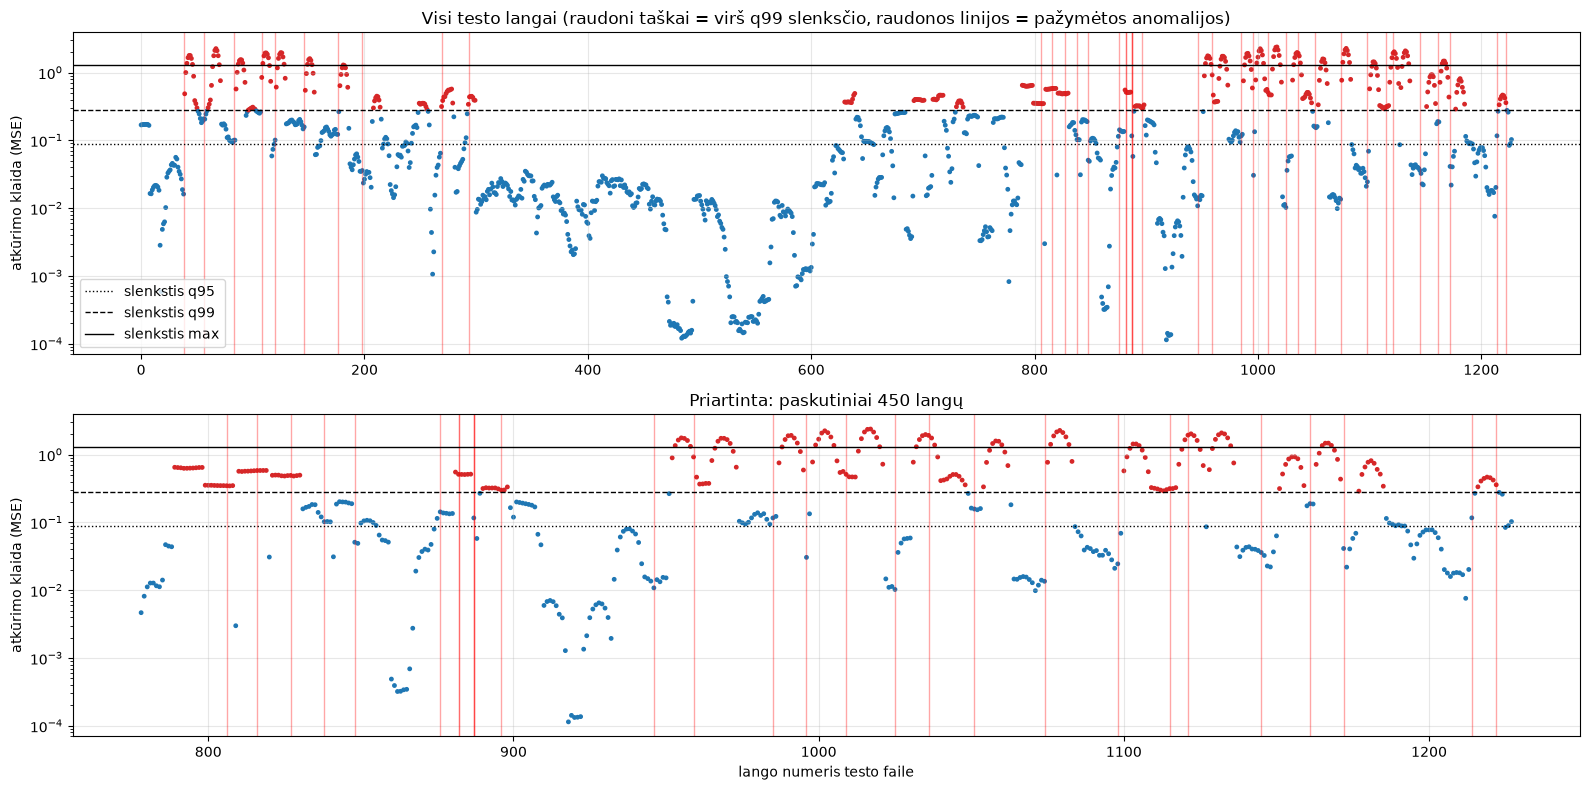

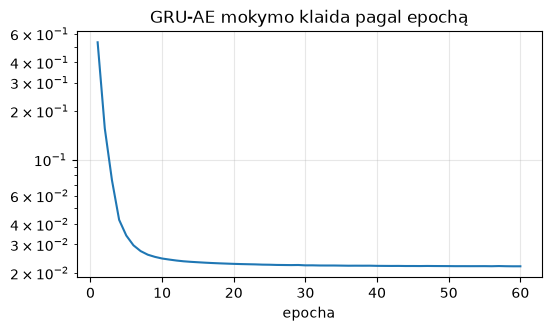

In [5]:
et, err, thr = SCORES["GRU-AE imu6 L=10 s0"]
pos = np.searchsorted(et, ANOM.to_numpy())               # where each labelled anomaly falls among the windows
x = np.arange(len(err))
fig, axes = plt.subplots(2, 1, figsize=(16, 8))
for ax, lo in zip(axes, [0, len(err) - 450]):
    sl = slice(lo, None)
    ax.scatter(x[sl], err[sl], s=6, c=np.where(err[sl] > thr["q99"], "tab:red", "tab:blue"))
    for p in pos[(pos >= lo)]:
        ax.axvline(p, color="red", alpha=0.35, lw=1)
    for name_, ls in zip(["q95", "q99", "max"], [":", "--", "-"]):
        ax.axhline(thr[name_], color="k", ls=ls, lw=1, label=f"slenkstis {name_}")
    ax.set_yscale("log"); ax.set_ylabel("atkūrimo klaida (MSE)"); ax.grid(alpha=0.3)
axes[0].set_title("Visi testo langai (raudoni taškai = virš q99 slenksčio, raudonos linijos = pažymėtos anomalijos)")
axes[1].set_title("Priartinta: paskutiniai 450 langų"); axes[1].set_xlabel("lango numeris testo faile"); axes[0].legend()
plt.tight_layout(); plt.show()

h = HIST["GRU-AE imu6 L=10 s0"]
plt.figure(figsize=(6, 3.2)); plt.plot(range(1, len(h) + 1), h); plt.yscale("log")
plt.title("GRU-AE mokymo klaida pagal epochą"); plt.xlabel("epocha"); plt.grid(alpha=0.3); plt.show()

## 7. Visų eksperimentų santrauka

Anomaly detection: 54 experiments | settings that were changed: model, features, window, hidden_layers, hidden, latent, threshold, match, seed, batch_size, params, epochs


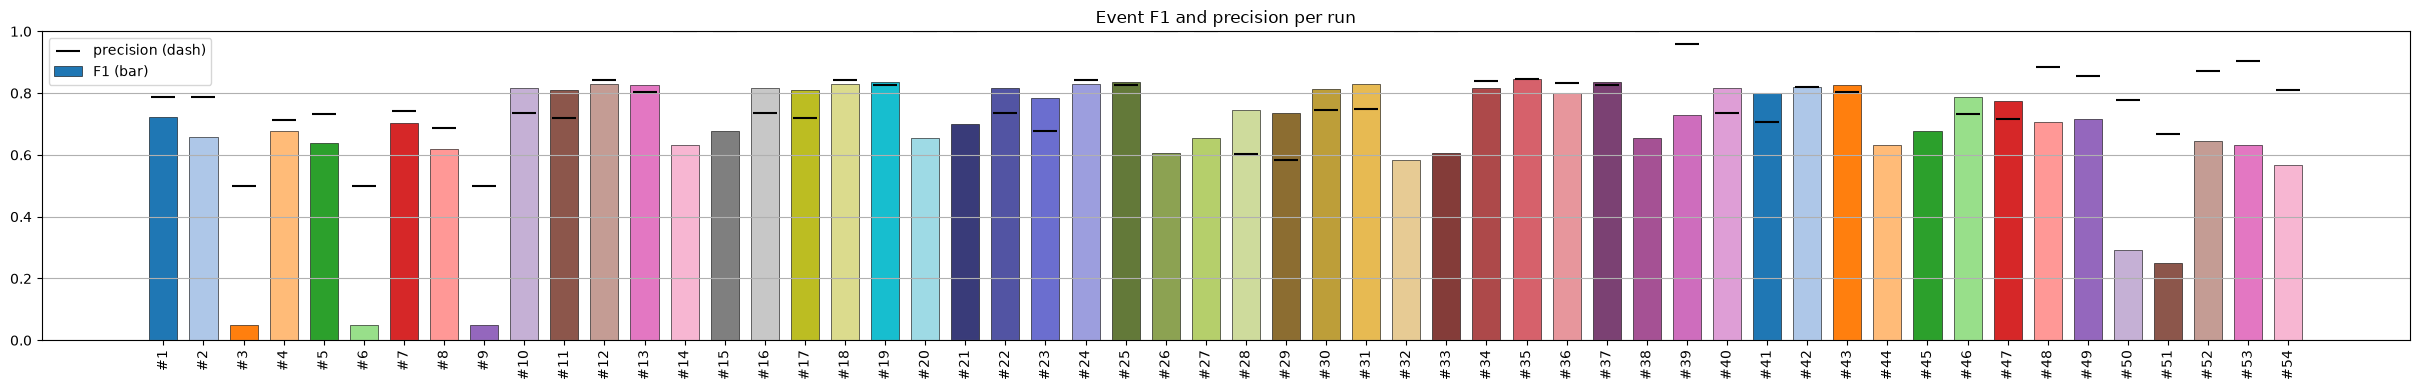

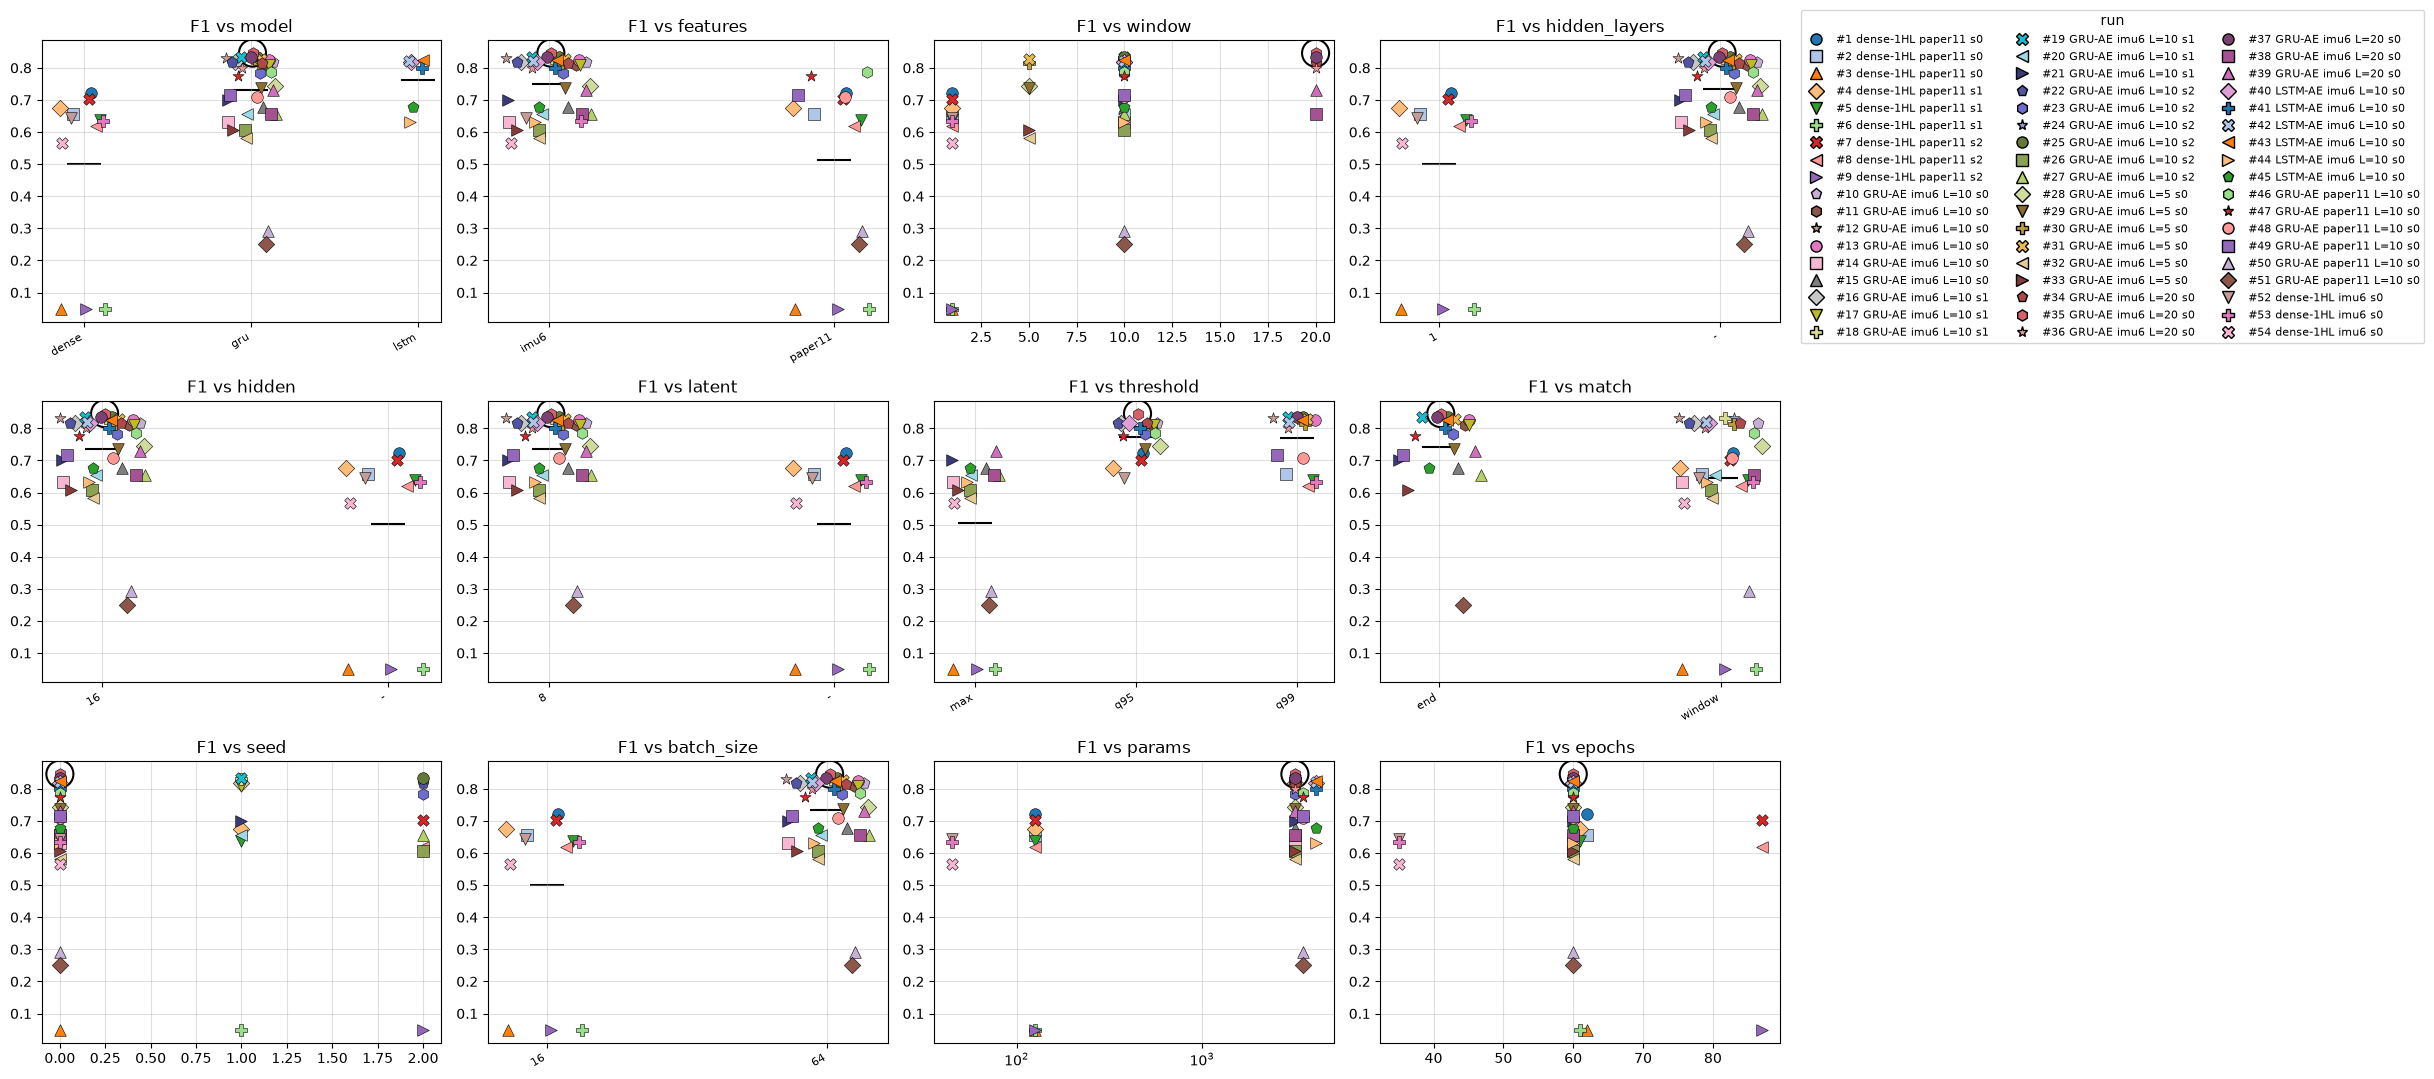

,run,name,model,features,window,hidden_layers,hidden,latent,threshold,match,seed,batch_size,params,epochs,precision,recall,f1,tp,fp,train_loss,sec
0,#35,GRU-AE imu6 L=20 s0,gru,imu6,20,nan,16.0000,8.0000,q95,end,0,64,3166,60,0.8460,0.8460,0.8460,33,6,0.0295,26.4000
1,#37,GRU-AE imu6 L=20 s0,gru,imu6,20,nan,16.0000,8.0000,q99,end,0,64,3166,60,0.8250,0.8460,0.8350,33,7,0.0295,26.4000
2,#25,GRU-AE imu6 L=10 s2,gru,imu6,10,nan,16.0000,8.0000,q99,end,2,64,3166,60,0.8250,0.8460,0.8350,33,7,0.0220,15.4000
3,#19,GRU-AE imu6 L=10 s1,gru,imu6,10,nan,16.0000,8.0000,q99,end,1,64,3166,60,0.8250,0.8460,0.8350,33,7,0.0237,15.4000
4,#18,GRU-AE imu6 L=10 s1,gru,imu6,10,nan,16.0000,8.0000,q99,window,1,64,3166,60,0.8420,0.8210,0.8310,32,6,0.0237,15.4000
5,#24,GRU-AE imu6 L=10 s2,gru,imu6,10,nan,16.0000,8.0000,q99,window,2,64,3166,60,0.8420,0.8210,0.8310,32,6,0.0220,15.4000
6,#12,GRU-AE imu6 L=10 s0,gru,imu6,10,nan,16.0000,8.0000,q99,window,0,64,3166,60,0.8420,0.8210,0.8310,32,6,0.0220,15.3000
7,#31,GRU-AE imu6 L=5 s0,gru,imu6,5,nan,16.0000,8.0000,q99,end,0,64,3166,60,0.7500,0.9230,0.8280,36,12,0.0156,8.1000
8,#43,LSTM-AE imu6 L=10 s0,lstm,imu6,10,nan,16.0000,8.0000,q99,end,0,64,4094,60,0.8050,0.8460,0.8250,33,8,0.0224,17.5000
9,#13,GRU-AE imu6 L=10 s0,gru,imu6,10,nan,16.0000,8.0000,q99,end,0,64,3166,60,0.8050,0.8460,0.8250,33,8,0.0220,15.3000


In [6]:
# ---- summary of ALL logged experiments in experiments_anomaly.csv (run on its own, any time) ----
# Finds every setting that differs between runs and compares the event F1 by each of them.
# Every run (= one CSV row) has its own colour + marker in all charts and in the table.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display

r = pd.read_csv("experiments_anomaly.csv").fillna({"notes": ""})
r.insert(0, "run", [f"#{i + 1}" for i in range(len(r))])
RESULTS = [c for c in ["precision", "recall", "f1", "tp", "fp", "train_loss", "sec"] if c in r]
changed = [c for c in r.columns if c not in RESULTS + ["run", "time", "name", "notes"] and r[c].nunique(dropna=False) > 1]
print(f"Anomaly detection: {len(r)} experiments | settings that were changed: {', '.join(changed)}")

COLORS = list(plt.cm.tab20.colors) + list(plt.cm.tab20b.colors)                  # 40 colours
MARKERS = ["o", "s", "^", "D", "v", "P", "X", "<", ">", "p", "h", "*"]
color = [COLORS[i % len(COLORS)] for i in range(len(r))]
marker = [MARKERS[(i // len(COLORS) + i) % len(MARKERS)] for i in range(len(r))]   # colour+marker pair is unique per run
best = r["f1"].idxmax()

def dots(a, xs, ys):
    for i, (xv, yv) in enumerate(zip(xs, ys)):
        a.scatter(xv, yv, color=color[i], marker=marker[i], s=70, edgecolor="k", linewidth=0.4, zorder=3)
    a.scatter(xs[best], ys[best], s=380, facecolor="none", edgecolor="k", linewidth=1.5, zorder=2)   # ring = best run

# 1) F1 (bar) and precision (dash) of every run
fig, ax = plt.subplots(figsize=(max(8, 0.45 * len(r)), 4))
x = np.arange(len(r))
ax.bar(x, r["f1"], 0.7, color=color, edgecolor="k", linewidth=0.4, label="F1 (bar)")
ax.scatter(x, r["precision"], marker="_", s=300, c="k", zorder=3, label="precision (dash)")
ax.set_ylim(max(0, 0.0), 1.0)
ax.set_xticks(x); ax.set_xticklabels(r["run"], rotation=90)
ax.set_title("Event F1 and precision per run"); ax.grid(axis="y"); ax.legend()
plt.tight_layout(); plt.show()

# 2) F1 against each changed setting (ring = best run)
ncol = 4
nrow = int(np.ceil(len(changed) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(18, 3.6 * nrow), squeeze=False)
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(r))
for a, c in zip(axes.ravel(), changed):
    v = r[c]
    if pd.api.types.is_numeric_dtype(v) and not pd.api.types.is_bool_dtype(v) and v.nunique() > 2:
        dots(a, v.to_numpy(), r["f1"].to_numpy())             # numeric setting
        if v.min() >= 0 and v.max() / max(v[v > 0].min(), 1e-12) >= 50:
            a.set_xscale("symlog", linthresh=v[v > 0].min())        # e.g. lr, l2, params span decades
    else:
        cats = v.map(lambda z: "-" if pd.isna(z) else f"{z:g}" if isinstance(z, (int, float)) and not isinstance(z, bool) else str(z))
        levels = sorted(cats.unique(), key=lambda s: (0, float(s), "") if s.lstrip("-").replace(".", "", 1).isdigit() else (1, 0, s))
        dots(a, cats.map(levels.index).to_numpy() + jitter, r["f1"].to_numpy())
        a.scatter(range(len(levels)), [r["f1"][cats == l].mean() for l in levels], marker="_", s=600, c="k")
        a.set_xticks(range(len(levels))); a.set_xticklabels(levels, rotation=30, ha="right", fontsize=8)
    a.set_title(f"F1 vs {c}"); a.grid(alpha=0.4)
for a in axes.ravel()[len(changed):]:
    a.axis("off")
handles = [plt.Line2D([], [], color=color[i], marker=marker[i], linestyle="", markersize=8, markeredgecolor="k",
                      label=f"{r['run'][i]} {r['name'][i]}") for i in range(len(r))]
fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0), ncol=1 + len(r) // 25, fontsize=8, title="run")
plt.tight_layout(); plt.show()

# 3) table: changed settings + results, best F1 first (run column = the run's colour)
table = r[["run", "name"] + changed + RESULTS].sort_values("f1", ascending=False)
run_color = dict(zip(r["run"], [to_hex(c_) for c_ in color]))
display(table.reset_index(drop=True).style
        .map(lambda v: f"background-color: {run_color[v]}", subset=["run"])
        .background_gradient(subset=["f1"], cmap="Greens").format(precision=4))